In [1]:
import json
from pathlib import Path
import pandas as pd
import spacy
from IPython.display import display

In [15]:
import os

In [16]:
print("Current working directory:", os.getcwd())

Current working directory: C:\Users\daoha\Downloads\IT_Tasks\BA_USDependency\eval_with_colab\annotation


In [19]:
GT_PATH = Path("baseline/20US_baseline.json")
PRED_PATH = Path("prediction/annotated_stories.json")

MODES = ["strict", "included", "relaxed"]

QUALIFIER_POS_TAGS = {"ADJ", "ADP", "ADV", "AUX", "CCONJ", "DET", "INTJ", "PUNCT", "SCONJ", "X"}

In [31]:
nlp = spacy.load("en_core_web_sm")

1. **Load Ground Truth and Predictions**: Load the ground truth and predictions from JSON files.
2. **Match Stories by Text**: Match stories from ground truth and predictions based on their text content.

In [32]:
def load_annotated_stories(path: Path) -> dict:
    print(path)
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def matching_stories_by_text(gt_stories: list[dict], pred_stories: list[dict]):
    remaining_pred_stories = list(pred_stories)
    matched_gt, match_pred = [], []

    for gt_story in gt_stories:
        gt_text = gt_story["Text"].strip()

        matched_index = next(
            (i for i,p in enumerate(remaining_pred_stories) if p["Text"] == gt_text), None
        )

        if matched_index is not None:
            matched_gt.append(gt_story)
            match_pred.append(remaining_pred_stories.pop(matched_index))

    extract_texts = {g["Text"].strip() for g in matched_gt}
    unmatched_gt = [g["Text"][:60] for g in gt_stories if g["Text"].strip() not in extract_texts]
    unmatched_pred = [p["Text"][:60] for p in remaining_pred_stories]

    return matched_gt, match_pred, unmatched_gt, unmatched_pred


gt_raw, pred_raw = None, None
try:
    gt_raw = load_annotated_stories(GT_PATH)
except FileNotFoundError:
    print(f"Ground truth file not found at {GT_PATH}. Please ensure the file exists.")

try:
    pred_raw = load_annotated_stories(PRED_PATH)
except FileNotFoundError:
    print(f"Predictions file not found at {PRED_PATH}. Please ensure the file exists.")

gt, pred = None, None
if pred_raw and gt_raw:
    gt, pred, unmatched_gt, unmatched_pred = matching_stories_by_text(gt_raw, pred_raw)
    print(f"Aligned {len(gt)} / {len(pred)} ground truth stories to a matching prediction.")
    if unmatched_gt:
        print(f"WARNING: Unmatched gold stories: {unmatched_gt}")
    if unmatched_pred:
        print(f"WARNING: Unmatched prediction stories: {unmatched_pred}")


baseline\20US_baseline.json
prediction\annotated_stories.json
Aligned 4 / 4 gold stories to a matching prediction.


### String-level matching rules

In [33]:
def normalize(text:str) -> str:
    return text.lower().strip()

#----------Extract---------------------#
def is_exact_match(phrase_a:str, phrase_b:str) -> bool:
    return normalize(phrase_a) == normalize(phrase_b)
#----------Included---------------------#
def is_included_match(phrase_a: str, phrase_b: str) -> bool:
    """True if the two phrases have the same word count and differ only by one pair of words where each is a substring of the other (e.g. a singular/plural pair), with every other word identical."""
    words_list_a = normalize(phrase_a).split()
    words_list_b = normalize(phrase_b).split()
    if len(words_list_a) != len(words_list_b):
        return False

    for word_x in words_list_a:
        for word_y in words_list_b:
            if word_x in word_y or word_y in word_x:
                rest_words_list_a = words_list_a.copy()
                rest_words_list_a.remove(word_x)

                rest_words_list_b = words_list_b.copy()
                rest_words_list_b.remove(word_y)
                if rest_words_list_a == rest_words_list_b:
                    return True
    return False

#------------------Relaxed-------------------#
def strip_qualifiers(text: str) -> str:
    """
    Drop function/qualifier words (POS-tagged via spaCy) and return what remains, e.g. "many datasets" -> "datasets".
    """
    doc = nlp(text)
    kept_words = []
    for token in doc:
        if token.pos_ not in QUALIFIER_POS_TAGS:
            kept_words.append(token.text)

    return " ".join(kept_words)


def is_relaxed_match(phrase_a: str, phrase_b: str) -> bool:
    if is_exact_match(phrase_a, phrase_b):
        return True
    return normalize(strip_qualifiers(phrase_a)) == normalize(strip_qualifiers(phrase_b))


### Pair-level rules

In [34]:
def compare_node_list(gt_items, pred_items, mode):
    gt_items = list(gt_items) # copy list
    true_positives = []
    remain_pred = []

    # Step 1 exact match
    for item in pred_items:
        match_index = None
        for i in range(len(gt_items)):
            if is_exact_match(item, gt_items[i]):
                match_index = i
                break

        if match_index is not None:
            matched_item = gt_items.pop(match_index)
            true_positives.append(matched_item)
        else:
            remain_pred.append(item)

    if mode == "strict":
        false_positives = remain_pred
        false_negatives = gt_items
        return true_positives, false_positives, false_negatives


    false_positives = []
    for predicted_item in remain_pred:
        match_index = None
        for i in range(len(gt_items)):
            if mode == "included":
                is_match = is_included_match(predicted_item, gt_items[i])
            else:  # relaxed
                is_match = is_relaxed_match(predicted_item, gt_items[i])
            if is_match:
                match_index = i
                break

        if match_index is not None:
            matched_item = gt_items.pop(match_index)
            true_positives.append(matched_item)
        else:
            false_positives.append(predicted_item)

    false_negatives = gt_items
    return true_positives, false_positives, false_negatives


In [35]:
def compare_edge_list(gt_edges, pred_edges, mode):
    gt_edges = [list(pair) for pair in gt_edges]  # copy
    true_positives = []
    leftover_predictions = []

    # step 1 exact match
    for predicted_pair in pred_edges:
        match_index = None
        for i in range(len(gt_edges)):
            gold_pair = gt_edges[i]
            first_matches = is_exact_match(predicted_pair[0], gold_pair[0])
            second_matches = is_exact_match(predicted_pair[1], gold_pair[1])
            if first_matches and second_matches:
                match_index = i
                break

        if match_index is not None:
            matched_pair = gt_edges.pop(match_index)
            true_positives.append(matched_pair)
        else:
            leftover_predictions.append(predicted_pair)

    if mode == "strict":
        false_positives = leftover_predictions
        false_negatives = gt_edges
        return true_positives, false_positives, false_negatives

    # Step 2 fall back
    false_positives = []
    for predicted_pair in leftover_predictions:
        match_index = None
        for i in range(len(gt_edges)):
            gold_pair = gt_edges[i]
            if mode == "included":
                first_matches = is_included_match(predicted_pair[0], gold_pair[0])
                second_matches = is_included_match(predicted_pair[1], gold_pair[1])
            else:  # relaxed
                first_matches = is_relaxed_match(predicted_pair[0], gold_pair[0])
                second_matches = is_relaxed_match(predicted_pair[1], gold_pair[1])

            if first_matches and second_matches:
                match_index = i
                break

        if match_index is not None:
            matched_pair = gt_edges.pop(match_index)
            true_positives.append(matched_pair)
        else:
            false_positives.append(predicted_pair)

    false_negatives = gt_edges
    return true_positives, false_positives, false_negatives


In [36]:
def precision_recall_f1(true_positive_count: int, false_positive_count: int, false_negative_count: int):
    precision = true_positive_count / (true_positive_count + false_positive_count) \
        if (true_positive_count + false_positive_count) else 0.0
    recall = true_positive_count / (true_positive_count + false_negative_count) \
        if (true_positive_count + false_negative_count) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return precision, recall, f1

In [42]:
SPAN_FIELD_NAMES = ["Persona", "GoalAction", "BenefitAction", "GoalEntity", "BenefitEntity", "benefit"]
PAIR_FIELD_NAMES = ["triggers", "targets", "contains"]

def getter_field_items(annotated_story, field_name):
    if field_name in ("GoalAction", "BenefitAction"):
        return annotated_story.get("Action", {}).get(field_name, [])
    elif field_name in ("GoalEntity", "BenefitEntity"):
        return annotated_story.get("Entity", {}).get(field_name, [])
    elif field_name in SPAN_FIELD_NAMES:
        return annotated_story.get(field_name, [])
    elif field_name in PAIR_FIELD_NAMES:
        return annotated_story.get(field_name, [])
    else:
        raise ValueError(f"Unknown field name: {field_name}")


In [43]:
def evaluate_field(gt_stories, predicted_stories, field_name, field_type, mode):
    total_true_positives = 0
    total_false_positives = 0
    total_false_negatives = 0
    per_story_scores = []

    for i in range(len(gt_stories)):
        gt_story = gt_stories[i]
        predicted_story = predicted_stories[i]

        gt_items = getter_field_items(gt_story, field_name)
        predicted_items = getter_field_items(predicted_story, field_name)

        if field_type == "span":
            true_positives, false_positives, false_negatives = compare_node_list(gt_items, predicted_items, mode)
        else:  # "pair"
            true_positives, false_positives, false_negatives = compare_edge_list(gt_items, predicted_items, mode)

        total_true_positives += len(true_positives)
        total_false_positives += len(false_positives)
        total_false_negatives += len(false_negatives)

        story_precision, story_recall, story_f1 = precision_recall_f1(
            len(true_positives), len(false_positives), len(false_negatives)
        )
        per_story_scores.append({"precision": story_precision, "recall": story_recall, "f1": story_f1})

    precision, recall, f1 = precision_recall_f1(
        total_true_positives, total_false_positives, total_false_negatives
    )
    overall_result = {
        "tp": total_true_positives,
        "fp": total_false_positives,
        "fn": total_false_negatives,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }
    return overall_result, per_story_scores


In [44]:
results = {}
per_story = {}

if pred is not None:
    for mode in MODES:
        results[mode] = {}
        per_story[mode] = {}

        for field_name in SPAN_FIELD_NAMES:
            overall_result, story_scores = evaluate_field(gt, pred, field_name, "span", mode)
            results[mode][field_name] = overall_result
            per_story[mode][field_name] = story_scores

        for field_name in PAIR_FIELD_NAMES:
            overall_result, story_scores = evaluate_field(gt, pred, field_name, "pair", mode)
            results[mode][field_name] = overall_result
            per_story[mode][field_name] = story_scores

    print("Done. Fields scored: " + str(SPAN_FIELD_NAMES + PAIR_FIELD_NAMES))

Done. Fields scored: ['Persona', 'GoalAction', 'BenefitAction', 'GoalEntity', 'BenefitEntity', 'benefit', 'triggers', 'targets', 'contains']


In [45]:
if pred is not None:
    all_field_names = SPAN_FIELD_NAMES + PAIR_FIELD_NAMES

    summary_rows = []
    for field_name in all_field_names:
        strict_f1 = results["strict"][field_name]["f1"]
        inclusion_f1 = results["included"][field_name]["f1"]
        relaxed_f1 = results["relaxed"][field_name]["f1"]
        summary_rows.append({
            "field": field_name,
            "strict_f1": strict_f1,
            "included_f1": inclusion_f1,
            "relaxed_f1": relaxed_f1,
        })

    summary = pd.DataFrame(summary_rows)
    summary = summary.set_index("field")
    summary = summary.round(3)
    display(summary)

,strict_f1,included_f1,relaxed_f1
field,,,
Persona,1.0,1.0,1.0
GoalAction,1.0,1.0,1.0
BenefitAction,1.0,1.0,1.0
GoalEntity,1.0,1.0,1.0
BenefitEntity,1.0,1.0,1.0
benefit,1.0,1.0,1.0
triggers,1.0,1.0,1.0
targets,1.0,1.0,1.0
contains,1.0,1.0,1.0


KeyError: 'inclusion_f1'

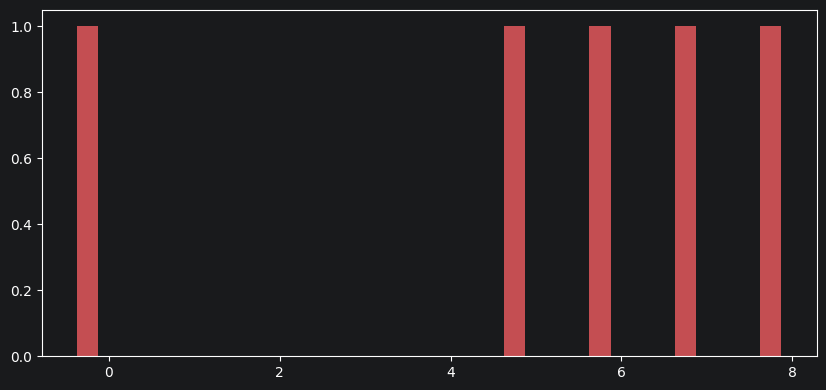

In [29]:
import matplotlib.pyplot as plt
import numpy as np

if pred is not None:
    field_names = summary.index.tolist()
    x_positions = np.arange(len(field_names))
    bar_width = 0.25
    mode_colors = {"strict_f1": "#C44E52", "inclusion_f1": "#4C72B0", "relaxed_f1": "#55A868"}

    fig, ax = plt.subplots(figsize=(10, 4.5))
    for offset, mode_column in enumerate(["strict_f1", "inclusion_f1", "relaxed_f1"]):
        ax.bar(
            x_positions + (offset - 1) * bar_width, summary[mode_column], bar_width,
            label=mode_column.replace("_f1", "").capitalize(), color=mode_colors[mode_column],
        )
    ax.set_xticks(x_positions)
    ax.set_xticklabels(field_names, rotation=30, ha="right")
    ax.set_ylabel("F1")
    ax.set_ylim(0, 1)
    ax.set_title("Pipeline F1 by field and comparison mode")
    ax.legend(title="Comparison mode")
    plt.tight_layout()
    plt.show()

In [30]:
if pred is not None:
    all_field_names = SPAN_FIELD_NAMES + PAIR_FIELD_NAMES

    story_rows = []
    for story_index in range(len(gt)):
        gt_story = gt[story_index]

        field_f1_scores = []
        for field_name in all_field_names:
            story_score = per_story["relaxed"][field_name][story_index]
            field_f1_scores.append(story_score["f1"])

        average_f1 = sum(field_f1_scores) / len(field_f1_scores)
        story_rows.append({
            "text_preview": gt_story["Text"][:70] + "...",
            "avg_f1_relaxed": average_f1,
        })

    story_df = pd.DataFrame(story_rows)
    story_df = story_df.sort_values("avg_f1_relaxed")
    story_df = story_df.reset_index(drop=True)
    display(story_df.round(3))

,text_preview,avg_f1_relaxed
0,"As a new user, I want to sign up using my emai...",0.444
1,"As a returning user, I want to log in my accou...",0.444
2,"As a user, I want to walk through a short, gui...",0.556
3,"As a traveler, I want to import a location fro...",0.556
